# 12. Deep Learning Sequence Investigation

## Objective

This notebook investigates whether the temporal football market value dataset
is suitable for sequence-based Deep Learning models such as Long Short-Term
Memory (LSTM).

The investigation focuses on:

- Number of historical snapshots available per player
- Distribution of observations across players
- Time gaps between consecutive player snapshots
- Availability of sequences of different lengths
- Number of sequences available for training, validation, and testing
- Suitability of the dataset for an LSTM-based future market value prediction model

The purpose of this notebook is to evaluate the temporal structure of the
dataset before implementing a Deep Learning model.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Locate project root
current_path = Path.cwd()

if current_path.name == "Experiment_2_Future_Prediction":
    project_root = current_path.parents[2]
else:
    project_root = current_path

data_path = project_root / "data" / "processed" / "temporal_market_value_dataset.csv"

print("Project root :", project_root)
print("Dataset path :", data_path)
print("Dataset exists:", data_path.exists())

# Load temporal dataset
df = pd.read_csv(data_path)

# Convert dates
df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])
df["target_date"] = pd.to_datetime(df["target_date"])

print("\nDataset shape:", df.shape)
print("Unique players:", df["player_id"].nunique())
print(
    "Snapshot range:",
    df["snapshot_date"].min().date(),
    "to",
    df["snapshot_date"].max().date()
)

df.head()

Project root : c:\Users\ngtht\football-prediction
Dataset path : c:\Users\ngtht\football-prediction\data\processed\temporal_market_value_dataset.csv
Dataset exists: True

Dataset shape: (213905, 26)
Unique players: 24275
Snapshot range: 2012-07-06 to 2025-12-22


,player_id,snapshot_date,target_date,future_date,target_distance_days,performance_window_start,current_market_value,age_at_snapshot,games_last_6m,goals_last_6m,assists_last_6m,minutes_last_6m,yellow_cards_last_6m,red_cards_last_6m,goals_per_90_last_6m,assists_per_90_last_6m,goal_contribution_per_90_last_6m,minutes_per_game_last_6m,height_in_cm,position,sub_position,foot,country_of_citizenship,future_market_value,future_value_change_eur,future_value_change_pct
0,4520,2012-07-06,2013-01-06,2013-01-12,6,2012-01-06,2500000,32.63,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,181.00,Defender,Centre-Back,right,Netherlands,2000000,-500000,-20.00
1,30003,2012-07-06,2013-01-06,2013-01-12,6,2012-01-06,5000000,25.88,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,176.00,Midfield,Defensive Midfield,right,NaN,4500000,-500000,-10.00
2,47740,2012-07-06,2013-01-06,2013-01-17,11,2012-01-06,400000,20.40,1.00,0.00,0.00,90.00,0.00,0.00,0.00,0.00,0.00,90.00,190.00,Defender,Centre-Back,both,Germany,600000,200000,50.00
3,60312,2012-07-06,2013-01-06,2013-01-17,11,2012-01-06,600000,23.76,1.00,1.00,1.00,45.00,0.00,0.00,NaN,NaN,NaN,45.00,175.00,Attack,Left Winger,right,Aruba,1250000,650000,108.33
4,80073,2012-07-06,2013-01-06,2013-01-09,3,2012-01-06,1500000,25.43,1.00,2.00,1.00,90.00,0.00,0.00,2.00,1.00,3.00,90.00,194.00,Attack,Centre-Forward,right,Netherlands,2000000,500000,33.33


In [3]:
snapshots_per_player = (
    df.groupby("player_id")
      .size()
      .sort_values(ascending=False)
)

snapshot_summary = snapshots_per_player.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

print("SNAPSHOTS PER PLAYER")
print("=" * 50)

print(snapshot_summary)

print("\nAdditional statistics")
print("-" * 50)
print(f"Total players        : {len(snapshots_per_player):,}")
print(f"Mean snapshots/player: {snapshots_per_player.mean():.2f}")
print(f"Median               : {snapshots_per_player.median():.0f}")
print(f"Minimum              : {snapshots_per_player.min()}")
print(f"Maximum              : {snapshots_per_player.max()}")

SNAPSHOTS PER PLAYER
count   24,275.00
mean         8.81
std          6.35
min          1.00
25%          4.00
50%          7.00
75%         13.00
90%         18.00
95%         21.00
max         35.00
dtype: float64

Additional statistics
--------------------------------------------------
Total players        : 24,275
Mean snapshots/player: 8.81
Median               : 7
Minimum              : 1
Maximum              : 35


In [4]:
sequence_thresholds = [2, 3, 4, 5, 6, 10]

sequence_availability = []

total_players = len(snapshots_per_player)

for threshold in sequence_thresholds:
    n_players = (snapshots_per_player >= threshold).sum()
    percentage = (n_players / total_players) * 100

    sequence_availability.append({
        "Minimum Snapshots": threshold,
        "Number of Players": n_players,
        "Percentage of Players": percentage
    })

sequence_availability_df = pd.DataFrame(sequence_availability)

sequence_availability_df

,Minimum Snapshots,Number of Players,Percentage of Players
0,2,22082,90.97
1,3,19829,81.68
2,4,18226,75.08
3,5,16609,68.42
4,6,15005,61.81
5,10,9665,39.81


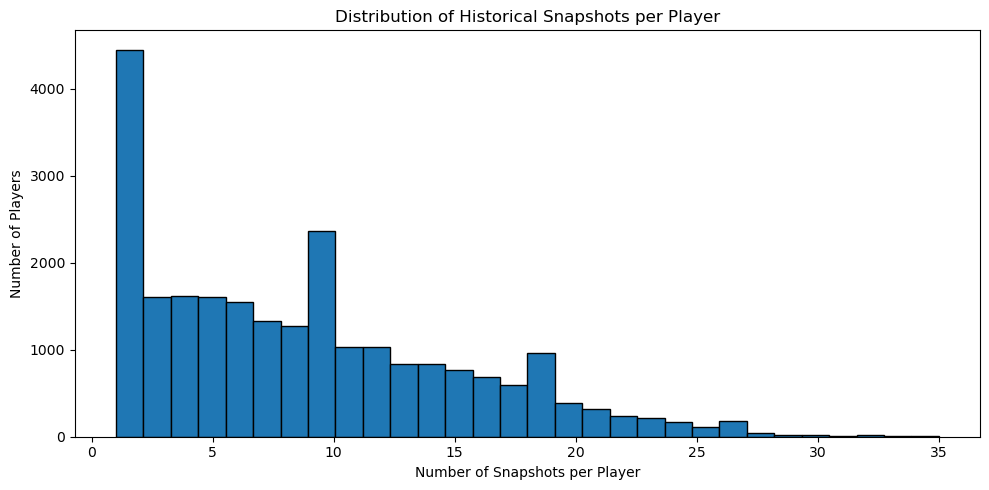

In [5]:
plt.figure(figsize=(10, 5))

plt.hist(
    snapshots_per_player,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Number of Snapshots per Player")
plt.ylabel("Number of Players")
plt.title("Distribution of Historical Snapshots per Player")

plt.tight_layout()
plt.show()

In [6]:
# Sort observations chronologically for each player
df_sorted = df.sort_values(
    ["player_id", "snapshot_date"]
).copy()

# Previous snapshot date for the same player
df_sorted["previous_snapshot_date"] = (
    df_sorted.groupby("player_id")["snapshot_date"].shift(1)
)

# Time gap between consecutive snapshots
df_sorted["snapshot_gap_days"] = (
    df_sorted["snapshot_date"] -
    df_sorted["previous_snapshot_date"]
).dt.days

# Remove the first observation of each player
gap_data = df_sorted["snapshot_gap_days"].dropna()

print("TIME GAP BETWEEN CONSECUTIVE SNAPSHOTS")
print("=" * 55)

print(
    gap_data.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nAdditional statistics")
print("-" * 55)
print(f"Number of valid gaps : {len(gap_data):,}")
print(f"Mean gap             : {gap_data.mean():.2f} days")
print(f"Median gap           : {gap_data.median():.0f} days")
print(f"Minimum gap          : {gap_data.min():.0f} days")
print(f"Maximum gap          : {gap_data.max():.0f} days")

TIME GAP BETWEEN CONSECUTIVE SNAPSHOTS
count   189,630.00
mean        210.47
std         163.01
min           1.00
25%         155.00
50%         179.00
75%         206.00
90%         321.00
95%         497.00
99%         903.00
max       3,613.00
Name: snapshot_gap_days, dtype: float64

Additional statistics
-------------------------------------------------------
Number of valid gaps : 189,630
Mean gap             : 210.47 days
Median gap           : 179 days
Minimum gap          : 1 days
Maximum gap          : 3613 days


In [8]:
gap_thresholds = [30, 60, 90, 120, 180, 270, 365]

gap_summary = []

total_gaps = len(gap_data)

for threshold in gap_thresholds:
    count = (gap_data <= threshold).sum()
    percentage = (count / total_gaps) * 100

    gap_summary.append({
        "Maximum Gap (Days)": threshold,
        "Number of Gaps": count,
        "Percentage of Gaps": percentage
    })

gap_summary_df = pd.DataFrame(gap_summary)

gap_summary_df

,Maximum Gap (Days),Number of Gaps,Percentage of Gaps
0,30,993,0.52
1,60,4083,2.15
2,90,16243,8.57
3,120,23144,12.20
4,180,97135,51.22
5,270,164883,86.95
6,365,173890,91.70


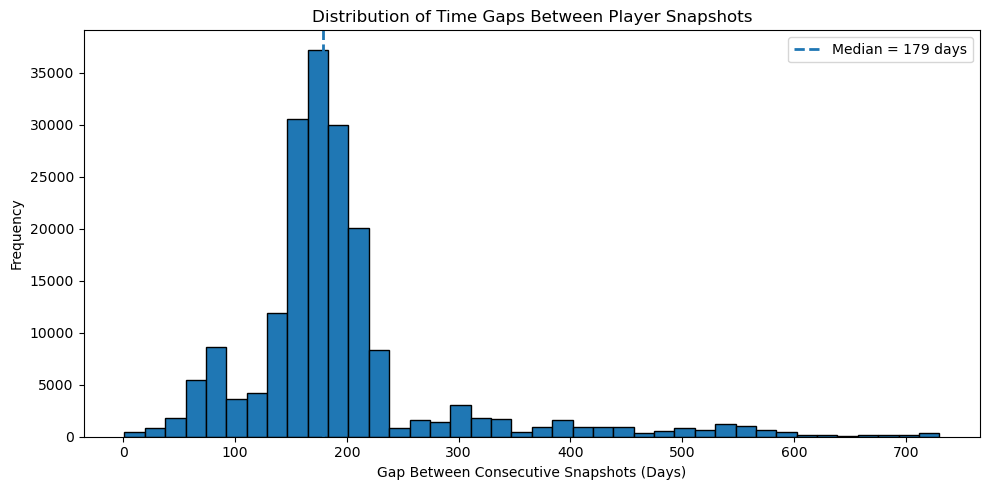

In [7]:
# Limit the visualisation to gaps <= 730 days
# so extreme outliers do not dominate the chart.

gap_plot_data = gap_data[gap_data <= 730]

plt.figure(figsize=(10, 5))

plt.hist(
    gap_plot_data,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    gap_data.median(),
    linestyle="--",
    linewidth=2,
    label=f"Median = {gap_data.median():.0f} days"
)

plt.xlabel("Gap Between Consecutive Snapshots (Days)")
plt.ylabel("Frequency")
plt.title("Distribution of Time Gaps Between Player Snapshots")

plt.legend()
plt.tight_layout()
plt.show()

In [9]:
gap_ranges = [
    ("90–270 days", 90, 270),
    ("120–240 days", 120, 240),
    ("150–210 days", 150, 210),
    ("150–240 days", 150, 240),
]

regularity_results = []

for label, lower, upper in gap_ranges:
    count = gap_data.between(lower, upper).sum()
    percentage = count / len(gap_data) * 100

    regularity_results.append({
        "Gap Range": label,
        "Number of Gaps": count,
        "Percentage": percentage
    })

gap_regularity_df = pd.DataFrame(regularity_results)

gap_regularity_df

,Gap Range,Number of Gaps,Percentage
0,90–270 days,149040,78.60
1,120–240 days,140368,74.02
2,150–210 days,106240,56.02
3,150–240 days,122284,64.49


In [10]:
sequence_lengths = [3, 4, 5]

sequence_results = []

for seq_len in sequence_lengths:

    possible_sequences = (
        snapshots_per_player - seq_len + 1
    ).clip(lower=0)

    total_sequences = int(possible_sequences.sum())

    eligible_players = int(
        (snapshots_per_player >= seq_len).sum()
    )

    sequence_results.append({
        "Sequence Length": seq_len,
        "Eligible Players": eligible_players,
        "Percentage of Players": (
            eligible_players / len(snapshots_per_player) * 100
        ),
        "Raw Possible Sequences": total_sequences
    })

raw_sequence_df = pd.DataFrame(sequence_results)

raw_sequence_df

,Sequence Length,Eligible Players,Percentage of Players,Raw Possible Sequences
0,3,19829,81.68,167548
1,4,18226,75.08,147719
2,5,16609,68.42,129493


## Sequence Design Decision

Based on the temporal investigation, a sequence length of 3 observations is
selected for the initial LSTM experiment.

The decision is based on the following evidence:

- 81.68% of players have at least 3 historical snapshots.
- A sequence length of 3 provides 167,548 raw possible sequences.
- The median gap between consecutive observations is 179 days.
- 64.49% of consecutive snapshot gaps fall between 150 and 240 days.
- Three historical observations therefore provide approximately one year of
  historical player trajectory under the typical observation interval.

The LSTM will use three consecutive historical observations to predict the
player's future market value approximately six months after the final
observation in the sequence.

Because the temporal observations are not perfectly regularly spaced,
additional gap constraints will be investigated before constructing the final
LSTM dataset.

In [11]:
sequence_length = 3

gap_limits = [240, 270, 365]

valid_sequence_results = []

# Ensure chronological ordering
df_sequence = df.sort_values(
    ["player_id", "snapshot_date"]
).copy()

for max_gap in gap_limits:

    total_sequences = 0
    players_with_valid_sequences = set()

    for player_id, player_data in df_sequence.groupby("player_id"):

        player_data = player_data.sort_values("snapshot_date").reset_index(drop=True)

        if len(player_data) < sequence_length:
            continue

        dates = player_data["snapshot_date"]

        for start_idx in range(len(player_data) - sequence_length + 1):

            sequence_dates = dates.iloc[
                start_idx:start_idx + sequence_length
            ]

            gaps = sequence_dates.diff().dt.days.dropna()

            # All consecutive gaps must satisfy the maximum-gap rule
            if (gaps <= max_gap).all():

                total_sequences += 1
                players_with_valid_sequences.add(player_id)

    valid_sequence_results.append({
        "Maximum Allowed Gap": max_gap,
        "Valid Sequences": total_sequences,
        "Players Represented": len(players_with_valid_sequences),
        "Sequence Retention (%)": (
            total_sequences / 167548 * 100
        )
    })

valid_sequence_comparison = pd.DataFrame(valid_sequence_results)

valid_sequence_comparison

,Maximum Allowed Gap,Valid Sequences,Players Represented,Sequence Retention (%)
0,240,126356,18599,75.41
1,270,128504,18642,76.70
2,365,142793,18906,85.23


## Final Sequence Construction Rule

For the initial LSTM experiment, the following sequence design is selected:

- Sequence length: 3 historical observations
- Maximum allowed gap between consecutive observations: 240 days
- Input features:
  - current_market_value
  - age_at_snapshot
  - minutes_last_6m
  - goals_last_6m
- Prediction target: future_market_value approximately six months after the
  final observation in the sequence

The 240-day maximum-gap constraint retains 126,356 valid raw sequences
representing 18,599 players, equivalent to 75.41% of all raw length-3
sequences.

This threshold was selected as a compromise between temporal consistency and
data retention. The dataset has a median consecutive observation gap of
179 days, and 64.49% of individual gaps fall between 150 and 240 days.
Therefore, allowing a maximum gap of 240 days accommodates the dominant
observation pattern while excluding unusually long interruptions between
sequence observations.

In [12]:
SEQUENCE_LENGTH = 3
MAX_GAP_DAYS = 240

sequence_metadata = []

df_sequence = (
    df.sort_values(["player_id", "snapshot_date"])
      .reset_index(drop=True)
      .copy()
)

for player_id, player_data in df_sequence.groupby("player_id"):

    player_data = (
        player_data
        .sort_values("snapshot_date")
        .reset_index()
    )

    if len(player_data) < SEQUENCE_LENGTH:
        continue

    for start_idx in range(len(player_data) - SEQUENCE_LENGTH + 1):

        seq = player_data.iloc[
            start_idx:start_idx + SEQUENCE_LENGTH
        ]

        gaps = seq["snapshot_date"].diff().dt.days.dropna()

        if (gaps <= MAX_GAP_DAYS).all():

            final_row = seq.iloc[-1]

            sequence_metadata.append({
                "player_id": player_id,

                "sequence_start_date":
                    seq.iloc[0]["snapshot_date"],

                "sequence_middle_date":
                    seq.iloc[1]["snapshot_date"],

                "sequence_end_date":
                    final_row["snapshot_date"],

                "target_date":
                    final_row["target_date"],

                "future_market_value":
                    final_row["future_market_value"],

                "gap_1_days":
                    gaps.iloc[0],

                "gap_2_days":
                    gaps.iloc[1],

                # Preserve original dataframe indices.
                "row_idx_t_minus_2":
                    seq.iloc[0]["index"],

                "row_idx_t_minus_1":
                    seq.iloc[1]["index"],

                "row_idx_t":
                    seq.iloc[2]["index"]
            })

sequence_metadata_df = pd.DataFrame(sequence_metadata)

print("Valid sequences:", f"{len(sequence_metadata_df):,}")
print(
    "Players represented:",
    f"{sequence_metadata_df['player_id'].nunique():,}"
)

sequence_metadata_df.head()

Valid sequences: 126,356
Players represented: 18,599


,player_id,sequence_start_date,sequence_middle_date,sequence_end_date,target_date,future_market_value,gap_1_days,gap_2_days,row_idx_t_minus_2,row_idx_t_minus_1,row_idx_t
0,10,2013-01-14,2013-06-19,2014-01-07,2014-07-07,1000000,156.00,202.00,0,1,2
1,10,2013-06-19,2014-01-07,2014-07-07,2015-01-07,1000000,202.00,181.00,1,2,3
2,10,2014-01-07,2014-07-07,2015-01-07,2015-07-07,1000000,181.00,184.00,2,3,4
3,10,2014-07-07,2015-01-07,2015-07-01,2016-01-01,1000000,184.00,175.00,3,4,5
4,26,2014-07-10,2015-02-04,2015-07-01,2016-01-01,1000000,209.00,147.00,7,8,9


In [13]:
print("SEQUENCE TEMPORAL COVERAGE")
print("=" * 55)

print(
    "Sequence start:",
    sequence_metadata_df["sequence_start_date"].min().date(),
    "to",
    sequence_metadata_df["sequence_start_date"].max().date()
)

print(
    "Sequence end:",
    sequence_metadata_df["sequence_end_date"].min().date(),
    "to",
    sequence_metadata_df["sequence_end_date"].max().date()
)

print(
    "Target date:",
    sequence_metadata_df["target_date"].min().date(),
    "to",
    sequence_metadata_df["target_date"].max().date()
)

print("\nGap summary:")
print(
    sequence_metadata_df[
        ["gap_1_days", "gap_2_days"]
    ].describe()
)

SEQUENCE TEMPORAL COVERAGE
Sequence start: 2012-07-18 to 2025-06-17
Sequence end: 2012-09-09 to 2025-12-22
Target date: 2013-03-09 to 2026-06-22

Gap summary:
       gap_1_days  gap_2_days
count  126,356.00  126,356.00
mean       163.88      163.74
std         44.20       42.98
min          1.00        1.00
25%        147.00      148.00
50%        173.00      172.00
75%        195.00      193.00
max        240.00      240.00


## Temporal Train, Validation, and Test Split

To preserve the forecasting nature of the problem and prevent future
information from leaking into model development, the LSTM sequences are split
chronologically rather than randomly.

The split follows the same temporal evaluation philosophy used in the
tabular future market value prediction experiment:

- Training sequences use historical observations ending no later than
  3 August 2023, with prediction targets available by 30 December 2023.
- Validation sequences use final observations from 3 January 2024 to
  19 July 2024, with prediction targets available by 30 December 2024.
- Test sequences use final observations from 1 January 2025 onwards.

The periods between these sets act as temporal embargo periods. These gaps
reduce the risk that target information from an earlier set overlaps with
input information used by the following set.

No random train-test splitting is used.

In [15]:
# Temporal boundaries aligned with Experiment 2

TRAIN_END_SNAPSHOT = pd.Timestamp("2023-08-03")
TRAIN_END_TARGET = pd.Timestamp("2023-12-30")

VAL_START_SNAPSHOT = pd.Timestamp("2024-01-03")
VAL_END_SNAPSHOT = pd.Timestamp("2024-07-19")
VAL_END_TARGET = pd.Timestamp("2024-12-30")

TEST_START_SNAPSHOT = pd.Timestamp("2025-01-01")


# -----------------------------
# Training sequences
# -----------------------------
train_sequences = sequence_metadata_df[
    (sequence_metadata_df["sequence_end_date"] <= TRAIN_END_SNAPSHOT) &
    (sequence_metadata_df["target_date"] <= TRAIN_END_TARGET)
].copy()


# -----------------------------
# Validation sequences
# -----------------------------
val_sequences = sequence_metadata_df[
    (sequence_metadata_df["sequence_end_date"] >= VAL_START_SNAPSHOT) &
    (sequence_metadata_df["sequence_end_date"] <= VAL_END_SNAPSHOT) &
    (sequence_metadata_df["target_date"] <= VAL_END_TARGET)
].copy()


# -----------------------------
# Test sequences
# -----------------------------
test_sequences = sequence_metadata_df[
    sequence_metadata_df["sequence_end_date"] >= TEST_START_SNAPSHOT
].copy()


print("TEMPORAL SEQUENCE SPLIT")
print("=" * 60)

print(f"Train sequences      : {len(train_sequences):,}")
print(f"Validation sequences : {len(val_sequences):,}")
print(f"Test sequences       : {len(test_sequences):,}")

print("\nTotal selected       :",
      f"{len(train_sequences) + len(val_sequences) + len(test_sequences):,}")

print("\nExcluded / embargoed :",
      f"{len(sequence_metadata_df) - len(train_sequences) - len(val_sequences) - len(test_sequences):,}")

TEMPORAL SEQUENCE SPLIT
Train sequences      : 95,683
Validation sequences : 7,038
Test sequences       : 8,940

Total selected       : 111,661

Excluded / embargoed : 14,695


In [16]:
def describe_sequence_split(name, data):

    print(f"\n{name}")
    print("=" * 60)

    print(f"Sequences : {len(data):,}")
    print(f"Players   : {data['player_id'].nunique():,}")

    if len(data) > 0:

        print(
            "Sequence start:",
            data["sequence_start_date"].min().date(),
            "to",
            data["sequence_start_date"].max().date()
        )

        print(
            "Sequence end  :",
            data["sequence_end_date"].min().date(),
            "to",
            data["sequence_end_date"].max().date()
        )

        print(
            "Target date   :",
            data["target_date"].min().date(),
            "to",
            data["target_date"].max().date()
        )


describe_sequence_split(
    "TRAIN",
    train_sequences
)

describe_sequence_split(
    "VALIDATION",
    val_sequences
)

describe_sequence_split(
    "TEST",
    test_sequences
)


TRAIN
Sequences : 95,683
Players   : 15,944
Sequence start: 2012-07-18 to 2023-03-14
Sequence end  : 2012-09-09 to 2023-06-30
Target date   : 2013-03-09 to 2023-12-30

VALIDATION
Sequences : 7,038
Players   : 6,208
Sequence start: 2022-11-04 to 2024-03-26
Sequence end  : 2024-01-04 to 2024-06-30
Target date   : 2024-07-04 to 2024-12-30

TEST
Sequences : 8,940
Players   : 7,334
Sequence start: 2023-12-05 to 2025-06-17
Sequence end  : 2025-01-03 to 2025-12-22
Target date   : 2025-07-03 to 2026-06-22


In [17]:
print("TEMPORAL LEAKAGE CHECKS")
print("=" * 60)

# Training checks
train_snapshot_ok = (
    train_sequences["sequence_end_date"].max()
    <= TRAIN_END_SNAPSHOT
)

train_target_ok = (
    train_sequences["target_date"].max()
    <= TRAIN_END_TARGET
)

# Validation checks
val_start_ok = (
    val_sequences["sequence_end_date"].min()
    >= VAL_START_SNAPSHOT
)

val_end_ok = (
    val_sequences["sequence_end_date"].max()
    <= VAL_END_SNAPSHOT
)

val_target_ok = (
    val_sequences["target_date"].max()
    <= VAL_END_TARGET
)

# Test check
test_start_ok = (
    test_sequences["sequence_end_date"].min()
    >= TEST_START_SNAPSHOT
)


print("Train snapshot boundary :", train_snapshot_ok)
print("Train target boundary   :", train_target_ok)

print("Validation start        :", val_start_ok)
print("Validation end          :", val_end_ok)
print("Validation target       :", val_target_ok)

print("Test start              :", test_start_ok)


all_checks_passed = all([
    train_snapshot_ok,
    train_target_ok,
    val_start_ok,
    val_end_ok,
    val_target_ok,
    test_start_ok
])

print("\nAll temporal checks passed:", all_checks_passed)

TEMPORAL LEAKAGE CHECKS
Train snapshot boundary : True
Train target boundary   : True
Validation start        : True
Validation end          : True
Validation target       : True
Test start              : True

All temporal checks passed: True


In [18]:
LSTM_FEATURES = [
    "current_market_value",
    "age_at_snapshot",
    "minutes_last_6m",
    "goals_last_6m"
]

TARGET = "future_market_value"

print("LSTM input features:")
for i, feature in enumerate(LSTM_FEATURES, start=1):
    print(f"{i}. {feature}")

print("\nNumber of timesteps :", SEQUENCE_LENGTH)
print("Number of features  :", len(LSTM_FEATURES))
print("Prediction target   :", TARGET)

LSTM input features:
1. current_market_value
2. age_at_snapshot
3. minutes_last_6m
4. goals_last_6m

Number of timesteps : 3
Number of features  : 4
Prediction target   : future_market_value


In [19]:
def build_sequence_arrays(metadata_df, source_df, features):

    X = []
    y = []

    for _, row in metadata_df.iterrows():

        row_indices = [
            int(row["row_idx_t_minus_2"]),
            int(row["row_idx_t_minus_1"]),
            int(row["row_idx_t"])
        ]

        sequence_values = (
            source_df.loc[row_indices, features]
            .to_numpy(dtype=np.float32)
        )

        X.append(sequence_values)
        y.append(float(row["future_market_value"]))

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)

    return X, y


X_train, y_train = build_sequence_arrays(
    train_sequences,
    df_sequence,
    LSTM_FEATURES
)

X_val, y_val = build_sequence_arrays(
    val_sequences,
    df_sequence,
    LSTM_FEATURES
)

X_test, y_test = build_sequence_arrays(
    test_sequences,
    df_sequence,
    LSTM_FEATURES
)


print("SEQUENCE ARRAY SHAPES")
print("=" * 50)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val  :", X_val.shape)
print("y_val  :", y_val.shape)

print("\nX_test :", X_test.shape)
print("y_test :", y_test.shape)

SEQUENCE ARRAY SHAPES
X_train: (95683, 3, 4)
y_train: (95683,)

X_val  : (7038, 3, 4)
y_val  : (7038,)

X_test : (8940, 3, 4)
y_test : (8940,)


In [20]:
sample_index = 0

sample_sequence = pd.DataFrame(
    X_train[sample_index],
    columns=LSTM_FEATURES,
    index=["t-2", "t-1", "t"]
)

print("EXAMPLE LSTM INPUT SEQUENCE")
print("=" * 60)

display(sample_sequence)

print(
    "\nTarget future market value:",
    f"€{y_train[sample_index]:,.0f}"
)

EXAMPLE LSTM INPUT SEQUENCE


,current_market_value,age_at_snapshot,minutes_last_6m,goals_last_6m
t-2,"4,000,000.00",34.60,"1,660.00",11.00
t-1,"2,000,000.00",35.03,"1,192.00",5.00
t,"1,000,000.00",35.58,"1,040.00",5.00



Target future market value: €1,000,000


In [22]:
def check_array(name, X, y):

    print(f"\n{name}")
    print("=" * 50)

    print("X shape :", X.shape)
    print("y shape :", y.shape)

    print("NaN in X:", np.isnan(X).sum())
    print("NaN in y:", np.isnan(y).sum())

    print("Inf in X:", np.isinf(X).sum())
    print("Inf in y:", np.isinf(y).sum())

    print(
        "Target range:",
        f"€{y.min():,.0f}",
        "to",
        f"€{y.max():,.0f}"
    )


check_array("TRAIN", X_train, y_train)
check_array("VALIDATION", X_val, y_val)
check_array("TEST", X_test, y_test)


TRAIN
X shape : (95683, 3, 4)
y shape : (95683,)
NaN in X: 348
NaN in y: 0
Inf in X: 0
Inf in y: 0
Target range: €10,000 to €200,000,000

VALIDATION
X shape : (7038, 3, 4)
y shape : (7038,)
NaN in X: 3
NaN in y: 0
Inf in X: 0
Inf in y: 0
Target range: €10,000 to €200,000,000

TEST
X shape : (8940, 3, 4)
y shape : (8940,)
NaN in X: 0
NaN in y: 0
Inf in X: 0
Inf in y: 0
Target range: €10,000 to €200,000,000


In [23]:
def investigate_missing_values(name, X, features):

    print(f"\n{name}")
    print("=" * 60)

    # Missing values per feature
    for feature_idx, feature in enumerate(features):

        missing_count = np.isnan(
            X[:, :, feature_idx]
        ).sum()

        print(
            f"{feature:<25}: "
            f"{missing_count:,} missing values"
        )

    # Number of sequences containing at least one NaN
    sequences_with_nan = np.isnan(X).any(axis=(1, 2))

    print(
        "\nSequences containing NaN:",
        f"{sequences_with_nan.sum():,}"
    )

    print(
        "Percentage of sequences:",
        f"{sequences_with_nan.mean() * 100:.4f}%"
    )


investigate_missing_values(
    "TRAIN",
    X_train,
    LSTM_FEATURES
)

investigate_missing_values(
    "VALIDATION",
    X_val,
    LSTM_FEATURES
)

investigate_missing_values(
    "TEST",
    X_test,
    LSTM_FEATURES
)


TRAIN
current_market_value     : 0 missing values
age_at_snapshot          : 348 missing values
minutes_last_6m          : 0 missing values
goals_last_6m            : 0 missing values

Sequences containing NaN: 116
Percentage of sequences: 0.1212%

VALIDATION
current_market_value     : 0 missing values
age_at_snapshot          : 3 missing values
minutes_last_6m          : 0 missing values
goals_last_6m            : 0 missing values

Sequences containing NaN: 1
Percentage of sequences: 0.0142%

TEST
current_market_value     : 0 missing values
age_at_snapshot          : 0 missing values
minutes_last_6m          : 0 missing values
goals_last_6m            : 0 missing values

Sequences containing NaN: 0
Percentage of sequences: 0.0000%


In [24]:
def remove_nan_sequences(X, y, name):

    valid_mask = (
        ~np.isnan(X).any(axis=(1, 2))
        & ~np.isnan(y)
    )

    X_clean = X[valid_mask]
    y_clean = y[valid_mask]

    removed = len(X) - len(X_clean)

    print(f"{name}")
    print("=" * 50)
    print(f"Before  : {len(X):,}")
    print(f"Removed : {removed:,}")
    print(f"After   : {len(X_clean):,}")
    print(
        f"Retained: {len(X_clean) / len(X) * 100:.4f}%"
    )

    return X_clean, y_clean


X_train, y_train = remove_nan_sequences(
    X_train, y_train, "TRAIN"
)

print()

X_val, y_val = remove_nan_sequences(
    X_val, y_val, "VALIDATION"
)

print()

X_test, y_test = remove_nan_sequences(
    X_test, y_test, "TEST"
)

TRAIN
Before  : 95,683
Removed : 116
After   : 95,567
Retained: 99.8788%

VALIDATION
Before  : 7,038
Removed : 1
After   : 7,037
Retained: 99.9858%

TEST
Before  : 8,940
Removed : 0
After   : 8,940
Retained: 100.0000%


In [25]:
print("FINAL CLEAN ARRAY CHECK")
print("=" * 60)

datasets = {
    "Train": (X_train, y_train),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)
}

for name, (X_data, y_data) in datasets.items():

    print(f"\n{name}")
    print(f"X shape : {X_data.shape}")
    print(f"y shape : {y_data.shape}")

    print("NaN in X:", np.isnan(X_data).sum())
    print("NaN in y:", np.isnan(y_data).sum())

    print("Inf in X:", np.isinf(X_data).sum())
    print("Inf in y:", np.isinf(y_data).sum())

FINAL CLEAN ARRAY CHECK

Train
X shape : (95567, 3, 4)
y shape : (95567,)
NaN in X: 0
NaN in y: 0
Inf in X: 0
Inf in y: 0

Validation
X shape : (7037, 3, 4)
y shape : (7037,)
NaN in X: 0
NaN in y: 0
Inf in X: 0
Inf in y: 0

Test
X shape : (8940, 3, 4)
y shape : (8940,)
NaN in X: 0
NaN in y: 0
Inf in X: 0
Inf in y: 0


## Missing-Value Treatment

A small number of LSTM input sequences contained missing values in the
`age_at_snapshot` feature.

- Training: 116 sequences (0.1212%)
- Validation: 1 sequence (0.0142%)
- Test: 0 sequences

Because the proportion of affected sequences was extremely small, sequences
containing missing input values were removed rather than imputed.

This avoids introducing additional assumptions through imputation while
retaining virtually all available sequence data.

In [26]:
from sklearn.preprocessing import StandardScaler

In [27]:
# Create feature scaler
feature_scaler = StandardScaler()

# Original shapes
train_shape = X_train.shape
val_shape = X_val.shape
test_shape = X_test.shape

# Flatten only temporarily for scaler fitting
X_train_2d = X_train.reshape(-1, len(LSTM_FEATURES))
X_val_2d = X_val.reshape(-1, len(LSTM_FEATURES))
X_test_2d = X_test.reshape(-1, len(LSTM_FEATURES))

# IMPORTANT:
# Fit the scaler using TRAINING DATA ONLY
feature_scaler.fit(X_train_2d)

# Transform all three sets using the training-fitted scaler
X_train_scaled = feature_scaler.transform(X_train_2d).reshape(train_shape)
X_val_scaled = feature_scaler.transform(X_val_2d).reshape(val_shape)
X_test_scaled = feature_scaler.transform(X_test_2d).reshape(test_shape)

print("SCALED INPUT SHAPES")
print("=" * 50)

print("Train      :", X_train_scaled.shape)
print("Validation :", X_val_scaled.shape)
print("Test       :", X_test_scaled.shape)

SCALED INPUT SHAPES
Train      : (95567, 3, 4)
Validation : (7037, 3, 4)
Test       : (8940, 3, 4)


In [28]:
scaling_summary = pd.DataFrame({
    "Feature": LSTM_FEATURES,
    "Training Mean": feature_scaler.mean_,
    "Training Scale": feature_scaler.scale_
})

scaling_summary

,Feature,Training Mean,Training Scale
0,current_market_value,"4,070,050.52","9,267,628.95"
1,age_at_snapshot,26.80,4.24
2,minutes_last_6m,578.78,661.49
3,goals_last_6m,0.87,2.09


In [29]:
print("SCALED DATA CHECK")
print("=" * 60)

print("Train mean:")
print(
    X_train_scaled.reshape(-1, len(LSTM_FEATURES)).mean(axis=0)
)

print("\nTrain standard deviation:")
print(
    X_train_scaled.reshape(-1, len(LSTM_FEATURES)).std(axis=0)
)

print("\nNaN checks:")
print("Train      :", np.isnan(X_train_scaled).sum())
print("Validation :", np.isnan(X_val_scaled).sum())
print("Test       :", np.isnan(X_test_scaled).sum())

print("\nInf checks:")
print("Train      :", np.isinf(X_train_scaled).sum())
print("Validation :", np.isinf(X_val_scaled).sum())
print("Test       :", np.isinf(X_test_scaled).sum())

SCALED DATA CHECK
Train mean:
[ 3.8870839e-06  5.4429515e-06 -8.3691502e-06  1.7083239e-05]

Train standard deviation:
[0.9998823 0.9999589 0.9996966 1.0004613]

NaN checks:
Train      : 0
Validation : 0
Test       : 0

Inf checks:
Train      : 0
Validation : 0
Test       : 0


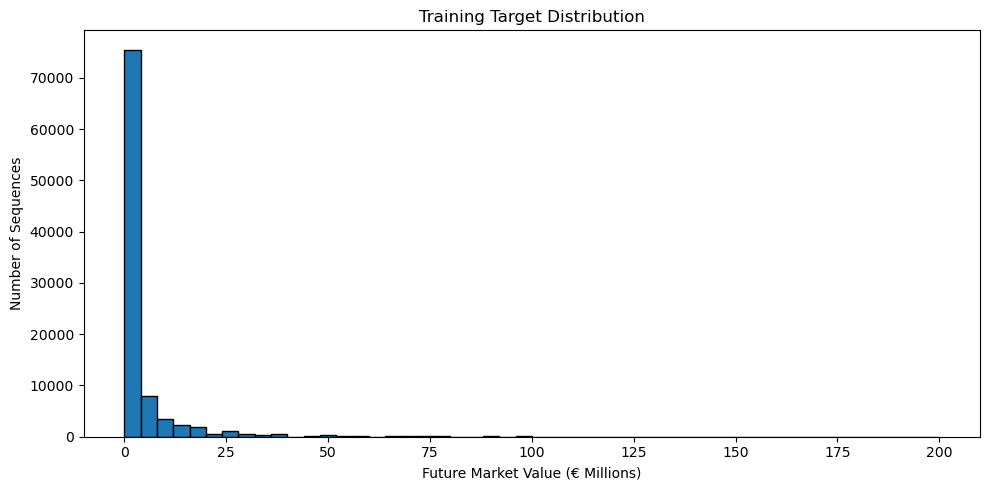

TARGET SUMMARY
Minimum : €10,000
Median  : €900,000
Mean    : €4,344,390
Maximum : €200,000,000


In [30]:
plt.figure(figsize=(10, 5))

plt.hist(
    y_train / 1_000_000,
    bins=50,
    edgecolor="black"
)

plt.xlabel("Future Market Value (€ Millions)")
plt.ylabel("Number of Sequences")
plt.title("Training Target Distribution")

plt.tight_layout()
plt.show()

print("TARGET SUMMARY")
print("=" * 50)

print(f"Minimum : €{y_train.min():,.0f}")
print(f"Median  : €{np.median(y_train):,.0f}")
print(f"Mean    : €{y_train.mean():,.0f}")
print(f"Maximum : €{y_train.max():,.0f}")

In [31]:
# Log-transform the prediction target
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

print("LOG-TRANSFORMED TARGET")
print("=" * 60)

print("Train")
print(f"Min    : {y_train_log.min():.4f}")
print(f"Median : {np.median(y_train_log):.4f}")
print(f"Mean   : {y_train_log.mean():.4f}")
print(f"Max    : {y_train_log.max():.4f}")

print("\nValidation shape:", y_val_log.shape)
print("Test shape      :", y_test_log.shape)

print("\nNaN checks:")
print("Train      :", np.isnan(y_train_log).sum())
print("Validation :", np.isnan(y_val_log).sum())
print("Test       :", np.isnan(y_test_log).sum())

LOG-TRANSFORMED TARGET
Train
Min    : 9.2104
Median : 13.7102
Mean   : 13.9484
Max    : 19.1138

Validation shape: (7037,)
Test shape      : (8940,)

NaN checks:
Train      : 0
Validation : 0
Test       : 0


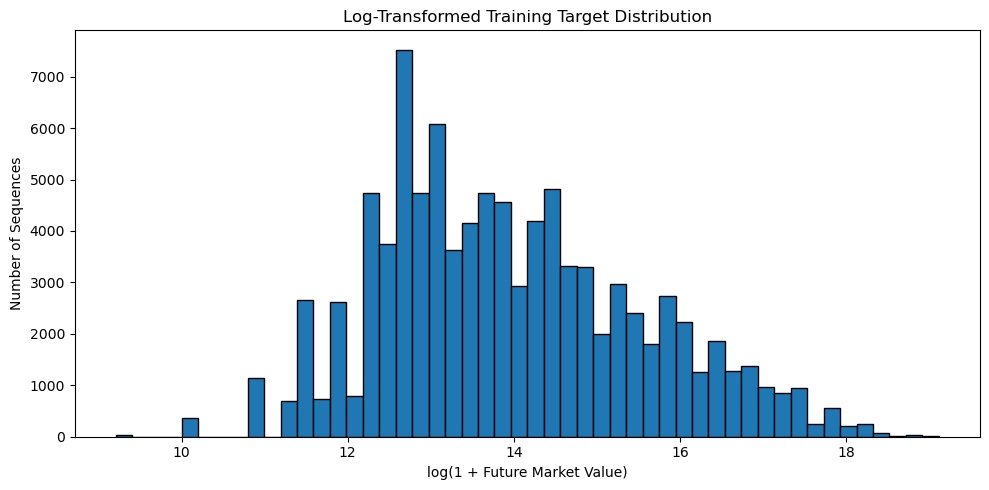

In [32]:
plt.figure(figsize=(10, 5))

plt.hist(
    y_train_log,
    bins=50,
    edgecolor="black"
)

plt.xlabel("log(1 + Future Market Value)")
plt.ylabel("Number of Sequences")
plt.title("Log-Transformed Training Target Distribution")

plt.tight_layout()
plt.show()

## Target Transformation

The future market value target is strongly right-skewed. In the training
sequences, the median future market value is approximately €0.9 million,
while the mean is approximately €4.34 million and the maximum reaches
€200 million.

For the initial LSTM experiment, the target is therefore transformed using:

`log(1 + future_market_value)`

This reduces the scale difference between low-value and very high-value
players and provides a more numerically stable target for neural-network
optimisation.

Model predictions will be transformed back to the original Euro scale using
the inverse `expm1` transformation before evaluation.

Therefore, R², MAE, and RMSE will still be calculated using market values in
Euros, allowing the LSTM results to be interpreted on the original target
scale.

In [34]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
c:\Users\ngtht\anaconda3\python.exe

Python version:
3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]


In [35]:
import sys

!{sys.executable} -m pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 1.1 MB/s eta 0:05:19
   ---------------------------------------- 0.8/351.2 MB 1.2 MB/s eta 0:04:48
   ---------------------------------------- 1.0/351.2 MB 1.3 MB/s eta 0:04:34
   ---------------------------------------- 1.3/351.2 MB 1.3 MB/s eta 0:04:37
   ---------------------------------------- 1.8/351.2 MB 1.4 MB/s eta 0:04:11
   ---------------------------------------- 2.1/351.2 MB 1.4 MB/s eta 0:04:04
   ---------------------------------------- 2.6/351.2 MB 1.5 MB/s eta 0:03:49
   ---------------------------------------- 3.1/351.2 MB 1.6 MB/s eta 0:03:36
   ---------------------------------------- 3.4/351.2 MB 1.7 MB/s eta 0:03:30
   ---------------------------------------- 3.9/351.2 MB 1.7 MB/s eta 0:03:20
    ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
googleapis-common-protos 1.72.0 requires protobuf!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
google-api-core 2.29.0 requires protobuf!=3.20.0,!=3.20.1,!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<7.0.0,>=3.19.5, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.
proto-plus 1.27.0 requires protobuf<7.0.0,>=3.19.0, but you have protobuf 7.36

In [36]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)
print("Keras version     :", tf.keras.__version__)

print("\nAvailable GPUs:")
print(tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Keras version     : 3.15.1

Available GPUs:
[]


In [37]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [38]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

lstm_model = Sequential([
    Input(
        shape=(
            SEQUENCE_LENGTH,
            len(LSTM_FEATURES)
        )
    ),

    LSTM(
        units=32,
        return_sequences=False
    ),

    Dropout(0.20),

    Dense(
        units=16,
        activation="relu"
    ),

    Dense(units=1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,281 (20.63 KB)

 Trainable params: 5,281 (20.63 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_scaled,
    y_train_log,

    validation_data=(
        X_val_scaled,
        y_val_log
    ),

    epochs=50,
    batch_size=256,

    callbacks=[early_stopping],

    verbose=1
)

Epoch 1/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 50.9245 - mae: 4.9047 - val_loss: 1.2893 - val_mae: 0.8926
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 2.4315 - mae: 1.2345 - val_loss: 0.6196 - val_mae: 0.6160
Epoch 3/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.9757 - mae: 1.1119 - val_loss: 0.4851 - val_mae: 0.5395
Epoch 4/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.7321 - mae: 1.0419 - val_loss: 0.5278 - val_mae: 0.5642
Epoch 5/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.5038 - mae: 0.9693 - val_loss: 0.5081 - val_mae: 0.5565
Epoch 6/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 1.2765 - mae: 0.8932 - val_loss: 0.5998 - val_mae: 0.6375
Epoch 7/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.0283 - mae: 0.8008 - val_loss: 0.6001 - val_mae: 0.6469
Epoch 8/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7810 - mae: 0.6929 - val_loss: 0.6457 - val_mae: 0.6807


In [40]:
history_df = pd.DataFrame(history.history)

best_epoch = history_df["val_loss"].idxmin() + 1
best_val_loss = history_df["val_loss"].min()

print("LSTM TRAINING SUMMARY")
print("=" * 50)

print(f"Epochs completed     : {len(history_df)}")
print(f"Best epoch           : {best_epoch}")
print(f"Best validation loss : {best_val_loss:.6f}")

display(history_df.tail(10))

LSTM TRAINING SUMMARY
Epochs completed     : 8
Best epoch           : 3
Best validation loss : 0.485135


,loss,mae,val_loss,val_mae
0,50.92,4.90,1.29,0.89
1,2.43,1.23,0.62,0.62
2,1.98,1.11,0.49,0.54
3,1.73,1.04,0.53,0.56
4,1.50,0.97,0.51,0.56
5,1.28,0.89,0.60,0.64
6,1.03,0.80,0.60,0.65
7,0.78,0.69,0.65,0.68


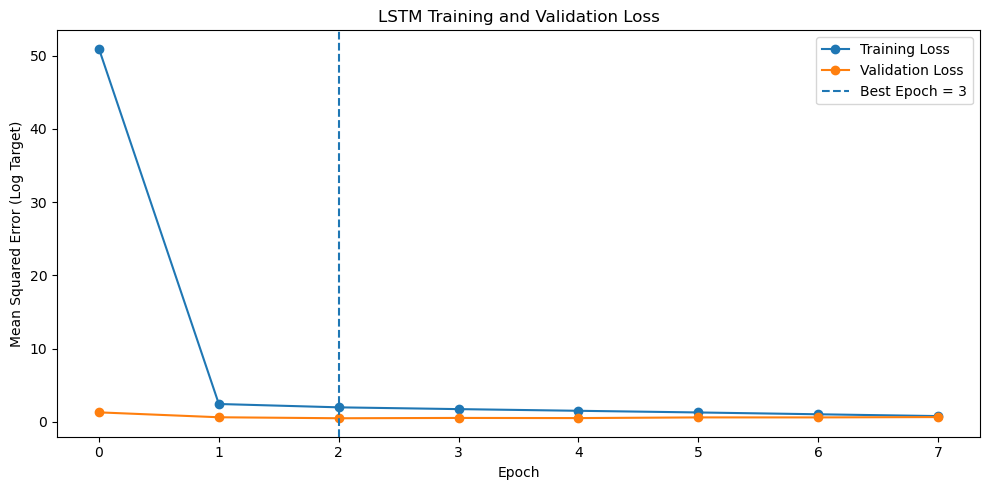

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    x=best_epoch - 1,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Log Target)")
plt.title("LSTM Training and Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

In [42]:
# Predict validation target in log space
y_val_pred_log = lstm_model.predict(
    X_val_scaled,
    verbose=0
).ravel()

# Convert predictions back to original Euro scale
y_val_pred = np.expm1(y_val_pred_log)

# Market value cannot be negative
y_val_pred = np.maximum(
    y_val_pred,
    0
)

print("VALIDATION PREDICTION CHECK")
print("=" * 60)

print("Prediction shape :", y_val_pred.shape)
print("Actual shape     :", y_val.shape)

print("\nPredicted range:")
print(
    f"€{y_val_pred.min():,.0f}",
    "to",
    f"€{y_val_pred.max():,.0f}"
)

print("\nActual range:")
print(
    f"€{y_val.min():,.0f}",
    "to",
    f"€{y_val.max():,.0f}"
)

print("\nNaN predictions :", np.isnan(y_val_pred).sum())
print("Inf predictions :", np.isinf(y_val_pred).sum())

VALIDATION PREDICTION CHECK
Prediction shape : (7037,)
Actual shape     : (7037,)

Predicted range:
€76,639 to €63,456,556

Actual range:
€10,000 to €200,000,000

NaN predictions : 0
Inf predictions : 0


In [43]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

lstm_val_r2 = r2_score(
    y_val,
    y_val_pred
)

lstm_val_mae = mean_absolute_error(
    y_val,
    y_val_pred
)

lstm_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_pred
    )
)

print("LSTM VALIDATION PERFORMANCE")
print("=" * 60)

print(f"R²   : {lstm_val_r2:.4f}")
print(f"MAE  : €{lstm_val_mae:,.0f}")
print(f"RMSE : €{lstm_val_rmse:,.0f}")

LSTM VALIDATION PERFORMANCE
R²   : 0.6036
MAE  : €2,615,894
RMSE : €8,055,602


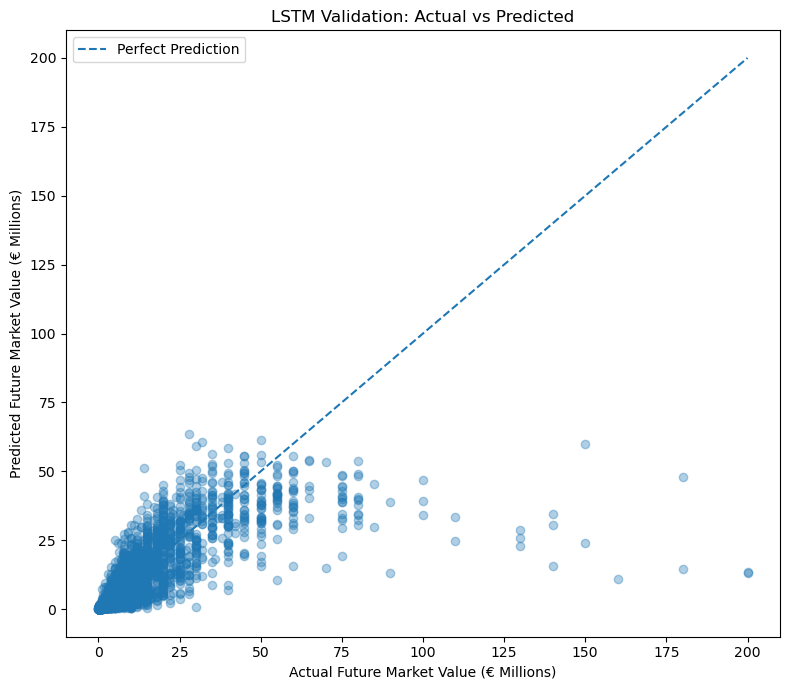

In [44]:
plt.figure(figsize=(8, 7))

plt.scatter(
    y_val / 1_000_000,
    y_val_pred / 1_000_000,
    alpha=0.35
)

max_value = max(
    y_val.max(),
    y_val_pred.max()
) / 1_000_000

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Future Market Value (€ Millions)")
plt.ylabel("Predicted Future Market Value (€ Millions)")
plt.title("LSTM Validation: Actual vs Predicted")

plt.legend()
plt.tight_layout()
plt.show()

## Initial LSTM Validation Result

The initial LSTM uses three historical observations, four input features,
standardised input variables, and a log-transformed future market value target.

Early stopping identified epoch 3 as the best validation epoch. Training loss
continued to decrease afterwards while validation loss increased, indicating
overfitting beyond the best epoch.

Validation performance on the original Euro scale was:

- R²: 0.6036
- MAE: €2,615,894
- RMSE: €8,055,602

The Actual vs Predicted analysis indicates that the model substantially
underpredicts some high-value observations. Because the target was trained in
log space, a controlled target-transformation experiment will be conducted
before changing the LSTM architecture.

The next experiment will retain the same data, sequence design, input
features, architecture, and validation set while replacing the log-transformed
target with a training-fitted standardised raw-Euro target.

In [45]:
from sklearn.preprocessing import StandardScaler

target_scaler = StandardScaler()

# Fit ONLY on training targets
y_train_scaled = target_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

# Transform validation and test using training scaler
y_val_scaled = target_scaler.transform(
    y_val.reshape(-1, 1)
).ravel()

y_test_scaled = target_scaler.transform(
    y_test.reshape(-1, 1)
).ravel()

print("RAW TARGET STANDARDISATION")
print("=" * 60)

print(
    f"Training target mean  : "
    f"€{target_scaler.mean_[0]:,.0f}"
)

print(
    f"Training target scale : "
    f"€{target_scaler.scale_[0]:,.0f}"
)

print("\nScaled training target:")
print(f"Mean : {y_train_scaled.mean():.6f}")
print(f"Std  : {y_train_scaled.std():.6f}")

print("\nNaN checks:")
print("Train      :", np.isnan(y_train_scaled).sum())
print("Validation :", np.isnan(y_val_scaled).sum())
print("Test       :", np.isnan(y_test_scaled).sum())

RAW TARGET STANDARDISATION
Training target mean  : €4,344,391
Training target scale : €10,229,640

Scaled training target:
Mean : -0.000000
Std  : 1.000000

NaN checks:
Train      : 0
Validation : 0
Test       : 0


In [ ]:
# Build LSTM Experiment B 
# Reset random seeds for a controlled comparison
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

lstm_raw_model = Sequential([
    Input(
        shape=(
            SEQUENCE_LENGTH,
            len(LSTM_FEATURES)
        )
    ),

    LSTM(
        units=32,
        return_sequences=False
    ),

    Dropout(0.20),

    Dense(
        units=16,
        activation="relu"
    ),

    Dense(units=1)
])

lstm_raw_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

lstm_raw_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,281 (20.63 KB)

 Trainable params: 5,281 (20.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train Experiment B
early_stopping_raw = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_raw = lstm_raw_model.fit(
    X_train_scaled,
    y_train_scaled,

    validation_data=(
        X_val_scaled,
        y_val_scaled
    ),

    epochs=50,
    batch_size=256,

    callbacks=[early_stopping_raw],

    verbose=1
)

Epoch 1/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.2103 - mae: 0.1807 - val_loss: 0.1200 - val_mae: 0.1382
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0808 - mae: 0.1181 - val_loss: 0.1004 - val_mae: 0.1276
Epoch 3/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0729 - mae: 0.1081 - val_loss: 0.0936 - val_mae: 0.1239
Epoch 4/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0708 - mae: 0.1038 - val_loss: 0.0910 - val_mae: 0.1224
Epoch 5/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0697 - mae: 0.1024 - val_loss: 0.0973 - val_mae: 0.1280
Epoch 6/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0689 - mae: 0.1014 - val_loss: 0.0939 - val_mae: 0.1242
Epoch 7/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0682 - mae: 0.1007 - val_loss: 0.0904 - val_mae: 0.1220
Epoch 8/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0674 - mae: 0.1002 - val_loss: 0.0927 - val_mae: 0.1245
Epoch 9/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - lo

In [48]:
history_raw_df = pd.DataFrame(history_raw.history)

best_epoch_raw = history_raw_df["val_loss"].idxmin() + 1
best_val_loss_raw = history_raw_df["val_loss"].min()

print("LSTM RAW-TARGET TRAINING SUMMARY")
print("=" * 60)

print(f"Epochs completed     : {len(history_raw_df)}")
print(f"Best epoch           : {best_epoch_raw}")
print(f"Best validation loss : {best_val_loss_raw:.6f}")

display(history_raw_df.tail(10))

LSTM RAW-TARGET TRAINING SUMMARY
Epochs completed     : 16
Best epoch           : 11
Best validation loss : 0.089944


,loss,mae,val_loss,val_mae
6,0.07,0.10,0.09,0.12
7,0.07,0.10,0.09,0.12
8,0.07,0.10,0.09,0.13
9,0.07,0.10,0.09,0.13
10,0.07,0.10,0.09,0.12
11,0.07,0.10,0.09,0.12
12,0.07,0.10,0.09,0.12
13,0.07,0.10,0.09,0.12
14,0.07,0.10,0.09,0.12
15,0.07,0.10,0.09,0.12


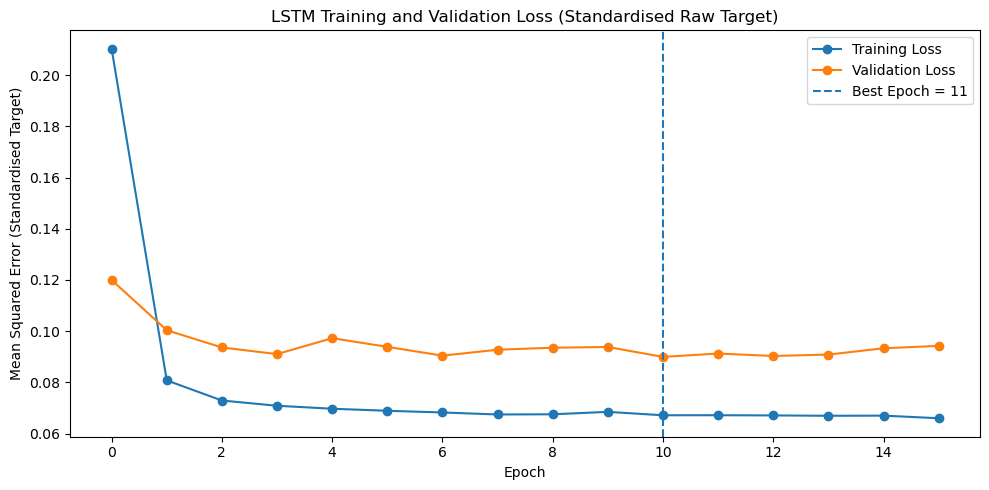

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_raw.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_raw.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.axvline(
    x=best_epoch_raw - 1,
    linestyle="--",
    label=f"Best Epoch = {best_epoch_raw}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Standardised Target)")
plt.title(
    "LSTM Training and Validation Loss "
    "(Standardised Raw Target)"
)

plt.legend()
plt.tight_layout()
plt.show()

In [50]:
# Predict standardised validation target
y_val_pred_scaled_raw = lstm_raw_model.predict(
    X_val_scaled,
    verbose=0
).reshape(-1, 1)

# Convert predictions back to Euros
y_val_pred_raw = target_scaler.inverse_transform(
    y_val_pred_scaled_raw
).ravel()

# Market value cannot be negative
y_val_pred_raw = np.maximum(
    y_val_pred_raw,
    0
)

print("RAW-TARGET VALIDATION PREDICTION CHECK")
print("=" * 60)

print("Prediction shape :", y_val_pred_raw.shape)
print("Actual shape     :", y_val.shape)

print("\nPredicted range:")
print(
    f"€{y_val_pred_raw.min():,.0f}",
    "to",
    f"€{y_val_pred_raw.max():,.0f}"
)

print("\nActual range:")
print(
    f"€{y_val.min():,.0f}",
    "to",
    f"€{y_val.max():,.0f}"
)

print("\nNaN predictions :", np.isnan(y_val_pred_raw).sum())
print("Inf predictions :", np.isinf(y_val_pred_raw).sum())

RAW-TARGET VALIDATION PREDICTION CHECK
Prediction shape : (7037,)
Actual shape     : (7037,)

Predicted range:
€0 to €175,271,424

Actual range:
€10,000 to €200,000,000

NaN predictions : 0
Inf predictions : 0


In [51]:
lstm_raw_val_r2 = r2_score(
    y_val,
    y_val_pred_raw
)

lstm_raw_val_mae = mean_absolute_error(
    y_val,
    y_val_pred_raw
)

lstm_raw_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_pred_raw
    )
)

print("LSTM STANDARDISED RAW-TARGET VALIDATION PERFORMANCE")
print("=" * 65)

print(f"R²   : {lstm_raw_val_r2:.4f}")
print(f"MAE  : €{lstm_raw_val_mae:,.0f}")
print(f"RMSE : €{lstm_raw_val_rmse:,.0f}")

LSTM STANDARDISED RAW-TARGET VALIDATION PERFORMANCE
R²   : 0.9425
MAE  : €1,253,545
RMSE : €3,067,942


In [52]:
lstm_target_comparison = pd.DataFrame({
    "LSTM Variant": [
        "Experiment A - Log Target",
        "Experiment B - Standardised Raw Target"
    ],

    "R2": [
        lstm_val_r2,
        lstm_raw_val_r2
    ],

    "MAE_EUR": [
        lstm_val_mae,
        lstm_raw_val_mae
    ],

    "RMSE_EUR": [
        lstm_val_rmse,
        lstm_raw_val_rmse
    ]
})

lstm_target_comparison

,LSTM Variant,R2,MAE_EUR,RMSE_EUR
0,Experiment A - Log Target,0.60,"2,615,893.75","8,055,601.75"
1,Experiment B - Standardised Raw Target,0.94,"1,253,545.25","3,067,942.28"
